# One-Month-Ahead Inflation Forecast, China: Neural Networks (MLP and LSTM)
Based on the course notebook **6_Volatility_Models_Neural_Networks**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, LSTM, Dropout

import warnings
warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')
tf.config.experimental.enable_op_determinism() #same results every time the notebook is run, for reproducebility

## 1. Group preprocessing

In [3]:
df = pd.read_csv(
    "china_economic_raw.csv",
    sep=";",
    na_values=["#DIV/0!", "#N/A", "#VALUE!", "#REF!"]
)

df.columns = df.columns.str.strip()

# Convert Date column
df["Date"] = pd.to_datetime(df["Date"], format="%b %y")

# Sort chronologically
df = df.sort_values("Date").reset_index(drop=True)

# Define target and predictors
target = "INFL"
predictors = [
    col for col in df.columns
    if col.startswith("X") and col[1:].isdigit()
]

# Basic inspection
print(df.shape)
print(df.head())
print(df.info())
print(df.describe())

# Convert predictors and target to numeric values

for col in predictors + ["INFL"]:
    original = df[col]

    converted = pd.to_numeric(
        original.astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

    # Check if conversion introduced additional NaNs
    new_missing = original.notna() & converted.isna()

    if new_missing.any():
        print(f"{col}: Unexpected values:")
        print(original[new_missing].unique()[:10])

    df[col] = converted

# Check whether all variables are numeric
print(df[predictors].dtypes.value_counts())

# Create a fresh copy of the dataset
data = df.sort_values("Date").reset_index(drop=True).copy()

# Convert all predictors to numeric
for col in predictors:
    original = data[col]

    converted = pd.to_numeric(
        original.astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False),
        errors="coerce"
    )

    # Check whether conversion creates new missing values
    new_missing = original.notna() & converted.isna()

    if new_missing.any():
        raise ValueError(
            f"Non-numeric values found in {col}: "
            f"{original[new_missing].unique()[:10]}"
        )

    data[col] = converted.astype(float)

# Keep original numeric values for duplicate detection
original_values = data[predictors].copy()

# Forward fill short gaps
data[predictors] = data[predictors].ffill(limit=2)

# Detect and merge duplicate features
features = predictors.copy()
merged_pairs = []

for i, keep in enumerate(predictors):
    if keep not in features:
        continue

    for remove in predictors[i + 1:]:
        if remove not in features:
            continue

        a = original_values[keep]
        b = original_values[remove]

        # Compare only observations where both have values
        overlap = a.notna() & b.notna()

        if overlap.sum() < 24:
            continue

        if a[overlap].nunique() < 3:
            continue

        # Check whether values match
        if np.allclose(
            a[overlap].to_numpy(dtype=float),
            b[overlap].to_numpy(dtype=float),
            rtol=1e-9,
            atol=1e-8
        ):

            # Combine available observations
            merged = a.combine_first(b)

            original_values[keep] = merged
            data[keep] = merged.ffill(limit=2)

            # Remove redundant column
            data = data.drop(columns=remove)
            features.remove(remove)

            merged_pairs.append((keep, remove))

print("Merged duplicate columns:", merged_pairs)
print("Remaining features:", len(features))

# Reference period for initial feature filtering
reference_mask = data["Date"].between(
    "2005-01-01", "2023-12-01"
)

# Missing values per feature
missing_ratio = (
    data.loc[reference_mask, features]
    .isna()
    .mean()
)

# Display highest missing ratios
print(
    (missing_ratio * 100)
    .sort_values(ascending=False)
    .head(20)
)

# Remove features with more than 20% missing
threshold = 0.20

drop_missing = missing_ratio[
    missing_ratio > threshold
].index.tolist()

# Identify constant features
drop_constant = [
    col for col in features
    if data.loc[
        reference_mask, col
    ].nunique(dropna=True) <= 1
]

# Combine exclusions
drop_features = list(set(
    drop_missing + drop_constant
))

# Remove features
data = data.drop(columns=drop_features)

features = [
    col for col in features
    if col not in drop_features
]

print("Dropped for missing values:", drop_missing)
print("Dropped constant features:", drop_constant)
print("Remaining features:", len(features))

FileNotFoundError: [Errno 2] No such file or directory: 'china_economic_raw.csv'

In [ ]:
# Shift all predictors by one month
X = data[features].shift(1).copy()

X.columns = [
    col + "_lag1" for col in features
]

# Historical inflation
X["INFL_lag1"] = data["INFL"].shift(1)
X["INFL_lag3"] = data["INFL"].shift(3)
X["INFL_lag12"] = data["INFL"].shift(12)

# Average inflation over the previous 3 months
X["INFL_mean3"] = (
    data["INFL"].shift(1).rolling(3).mean()
)

month = data["Date"].dt.month

X["month_sin"] = np.sin(2 * np.pi * month / 12)
X["month_cos"] = np.cos(2 * np.pi * month / 12)

# Combine target and engineered features
prepared = pd.concat(
    [data[["Date", "INFL"]], X],
    axis=1
)

# Keep only observations from 2005 onward
prepared = prepared[
    (prepared["Date"] >= "2005-01-01") &
    prepared["INFL"].notna()
].copy()

# Training observations only
outlier_train = prepared[
    prepared["Date"] < "2024-01-01"
].copy()

# Exclude binary and seasonal features from IQR audit
outlier_cols = [
    col for col in X.columns
    if col not in [
        "PMI_expansion_lag1",
        "month_sin",
        "month_cos"
    ]
]

Q1 = outlier_train[outlier_cols].quantile(0.25)
Q3 = outlier_train[outlier_cols].quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (outlier_train[outlier_cols] < Q1 - 1.5 * IQR) |
    (outlier_train[outlier_cols] > Q3 + 1.5 * IQR)
)

print(outliers.sum().sort_values(ascending=False).head(20))

# Chronological train-test split

# Training: January 2005 - December 2023
train = prepared[
    (prepared["Date"] >= "2005-01-01") &
    (prepared["Date"] < "2024-01-01")
].copy()

# Testing: January 2024 - April 2026
test = prepared[
    (prepared["Date"] >= "2024-01-01") &
    (prepared["Date"] <= "2026-04-01")
].copy()

# Separate predictors and target
X_train = train.drop(columns=["Date", "INFL"])
y_train = train["INFL"]

X_test = test.drop(columns=["Date", "INFL"])
y_test = test["INFL"]

# Check number of observations
print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 228 | Testing observations: 28 | Features: 167


## 2. Scaling and validation period
- Missing values are filled with the training median and all features are standardised (mean 0, std 1). Both are fitted on the training data only.
- The last 4 years of the training period (2020–2023) are used as a **validation period** to choose the number of epochs and batch size.

In [ ]:
imputer = SimpleImputer(strategy='median').fit(X_train)
scaler  = StandardScaler().fit(imputer.transform(X_train))
X_train_s = scaler.transform(imputer.transform(X_train))
X_test_s  = scaler.transform(imputer.transform(X_test))

# Validation split inside the training period
n_valid = 48 # 2020-01 to 2023-12
X_fit_s, y_fit = X_train_s[:-n_valid], y_train.values[:-n_valid]
X_val_s, y_val = X_train_s[-n_valid:], y_train.values[-n_valid:]
print('Fit:', len(y_fit), ' Validation:', len(y_val), ' Test:', len(y_test))

Fit: 180  Validation: 48  Test: 28


In [ ]:
def regression_metrics(actual, predicted):
    return {'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
            'MAE':  mean_absolute_error(actual, predicted),
            'R2':   r2_score(actual, predicted)}

benchmarks = {
    'Last-month inflation': X_test['INFL_lag1'].to_numpy(float),
    'Training mean':        np.full(len(y_test), float(y_train.mean())),
    'Same month last year': X_test['INFL_lag12'].to_numpy(float),
}

## 3. MLP neural network
Same architecture as the course: Dense(128, ReLU) → Dense(64, ReLU) → Dense(1, linear), loss = MSE, optimizer = Adam. We add ropout(0.2) after each hidden layer (randomly switches off 20% of neurons during training) to reduce overfitting.

In [ ]:
def build_mlp():
    model = Sequential([
        Input(shape=(X_train_s.shape[1],)),
        Dense(128, activation='relu'),
        Dropout(0.2),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(1, activation='linear')])
    model.compile(loss='mse', optimizer='adam')
    return model

epochs_trial = [20, 50, 100, 150]
batch_trial  = [16, 32]
mlp_search = []
for epochs in epochs_trial:
    for batch in batch_trial:
        tf.keras.utils.set_random_seed(1)# fixes numpy, python and tensorflow seeds
        model = build_mlp()
        model.fit(X_fit_s, y_fit, epochs=epochs, batch_size=batch, verbose=False)
        val_pred = model.predict(X_val_s, verbose=0).flatten()
        rmse = np.sqrt(mean_squared_error(y_val, val_pred))
        mlp_search.append((epochs, batch, rmse))
        print(f'epochs={epochs:<4} batch={batch:<3} validation RMSE={rmse:.4f}')

best_epochs, best_batch, _ = min(mlp_search, key=lambda t: t[2])
print('\nBest MLP: epochs =', best_epochs, ' batch size =', best_batch)

epochs=20   batch=16  validation RMSE=1.0535


epochs=20   batch=32  validation RMSE=1.0414


epochs=50   batch=16  validation RMSE=0.9677


epochs=50   batch=32  validation RMSE=1.1713


epochs=100  batch=16  validation RMSE=0.8520


epochs=100  batch=32  validation RMSE=0.9715


epochs=150  batch=16  validation RMSE=0.8037


epochs=150  batch=32  validation RMSE=0.9475

Best MLP: epochs = 150  batch size = 16


In [ ]:
# Final MLP: re-train on the full training period, then forecast the test period
tf.keras.utils.set_random_seed(1)
mlp = build_mlp()
mlp.fit(X_train_s, y_train.values, epochs=best_epochs, batch_size=best_batch, verbose=False)
mlp_pred = mlp.predict(X_test_s, verbose=0).flatten()
print('MLP test RMSE: %.4f' % np.sqrt(mean_squared_error(y_test, mlp_pred)))

MLP test RMSE: 0.3996


## 4. LSTM neural network 
the LSTM needs 3D input: (samples, time steps, features). `split_sequences` cuts the data into overlapping windows.
Window = 12 months instead of 20 days: each sample is the last 12 months of (already lagged) features, and the target is inflation in the month the window ends.
Sequences are built on the full 2005–2026 sample in date order, so the first test months can use late-2023 data as history (only past information is used).
Inputs are compressed to 10 principal components (about 86% of the variance, fitted on training data). With all 167 features the LSTM overfitted badly and did worse than every benchmark.

In [ ]:
n_steps = 12

# compress features to 10 principal components
pca = PCA(n_components=10, random_state=1).fit(X_train_s)
X_all_s = np.vstack([pca.transform(X_train_s), pca.transform(X_test_s)])
y_all   = np.concatenate([y_train.values, y_test.values])

def split_sequences(X, y, n_steps):
    X_seq, y_seq = [], []
    for i in range(n_steps, len(X) + 1):
        X_seq.append(X[i - n_steps:i])
        y_seq.append(y[i - 1])
    return np.array(X_seq), np.array(y_seq)

X_seq, y_seq = split_sequences(X_all_s, y_all, n_steps)
end_row = np.arange(n_steps - 1, len(X_all_s))

n_train = len(X_train_s)
is_fit  = end_row < n_train - n_valid
is_val  = (end_row >= n_train - n_valid) & (end_row < n_train)
is_test = end_row >= n_train
print('LSTM input shape (samples, time steps, features):', X_seq.shape)
print('Fit:', is_fit.sum(), ' Validation:', is_val.sum(), ' Test:', is_test.sum())
n_train_rows = n_train

LSTM input shape (samples, time steps, features): (245, 12, 10)
Fit: 169  Validation: 48  Test: 28


In [ ]:
def build_lstm():
    model = Sequential([
        Input(shape=(n_steps, X_seq.shape[2])),
        LSTM(128, activation='relu'),
        Dropout(0.2),
        Dense(1, activation='linear')])
    model.compile(optimizer='adam', loss='mean_squared_error')
    return model

lstm_search = []
for epochs in [20, 40, 60]:
    for batch in [16, 32]:
        tf.keras.utils.set_random_seed(1)
        model = build_lstm()
        model.fit(X_seq[is_fit], y_seq[is_fit], epochs=epochs, batch_size=batch, shuffle=False, verbose=False)
        val_pred = model.predict(X_seq[is_val], verbose=0).flatten()
        rmse = np.sqrt(mean_squared_error(y_seq[is_val], val_pred))
        lstm_search.append((epochs, batch, rmse))
        print(f'epochs={epochs:<4} batch={batch:<3} validation RMSE={rmse:.4f}')

best_epochs_l, best_batch_l, _ = min(lstm_search, key=lambda t: t[2])
print('\nBest LSTM: epochs =', best_epochs_l, ' batch size =', best_batch_l)

# Final LSTM: re-train on the full training period, forecast the test period
tf.keras.utils.set_random_seed(1)
lstm = build_lstm()
lstm.fit(X_seq[~is_test], y_seq[~is_test], epochs=best_epochs_l, batch_size=best_batch_l, shuffle=False, verbose=False)
lstm_pred = lstm.predict(X_seq[is_test], verbose=0).flatten()
print('LSTM test RMSE: %.4f' % np.sqrt(mean_squared_error(y_test, lstm_pred)))

epochs=20   batch=16  validation RMSE=0.9796


epochs=20   batch=32  validation RMSE=1.0455


epochs=40   batch=16  validation RMSE=1.3037


epochs=40   batch=32  validation RMSE=1.1168


epochs=60   batch=16  validation RMSE=1.5054


epochs=60   batch=32  validation RMSE=1.5502

Best LSTM: epochs = 20  batch size = 16


LSTM test RMSE: 0.6392


## 5. Results on the test period

In [ ]:
results = pd.DataFrame({'MLP':  regression_metrics(y_test, mlp_pred),
                        'LSTM': regression_metrics(y_test, lstm_pred),
                        **{name: regression_metrics(y_test, p) for name, p in benchmarks.items()}}).T
results.round(4)

,RMSE,MAE,R2
MLP,0.3996,0.3059,0.3934
LSTM,0.6392,0.4908,-0.5526
Last-month inflation,0.8988,0.6350,-2.0695
Training mean,0.5171,0.3620,-0.0160
Same month last year,0.9757,0.6629,-2.6172


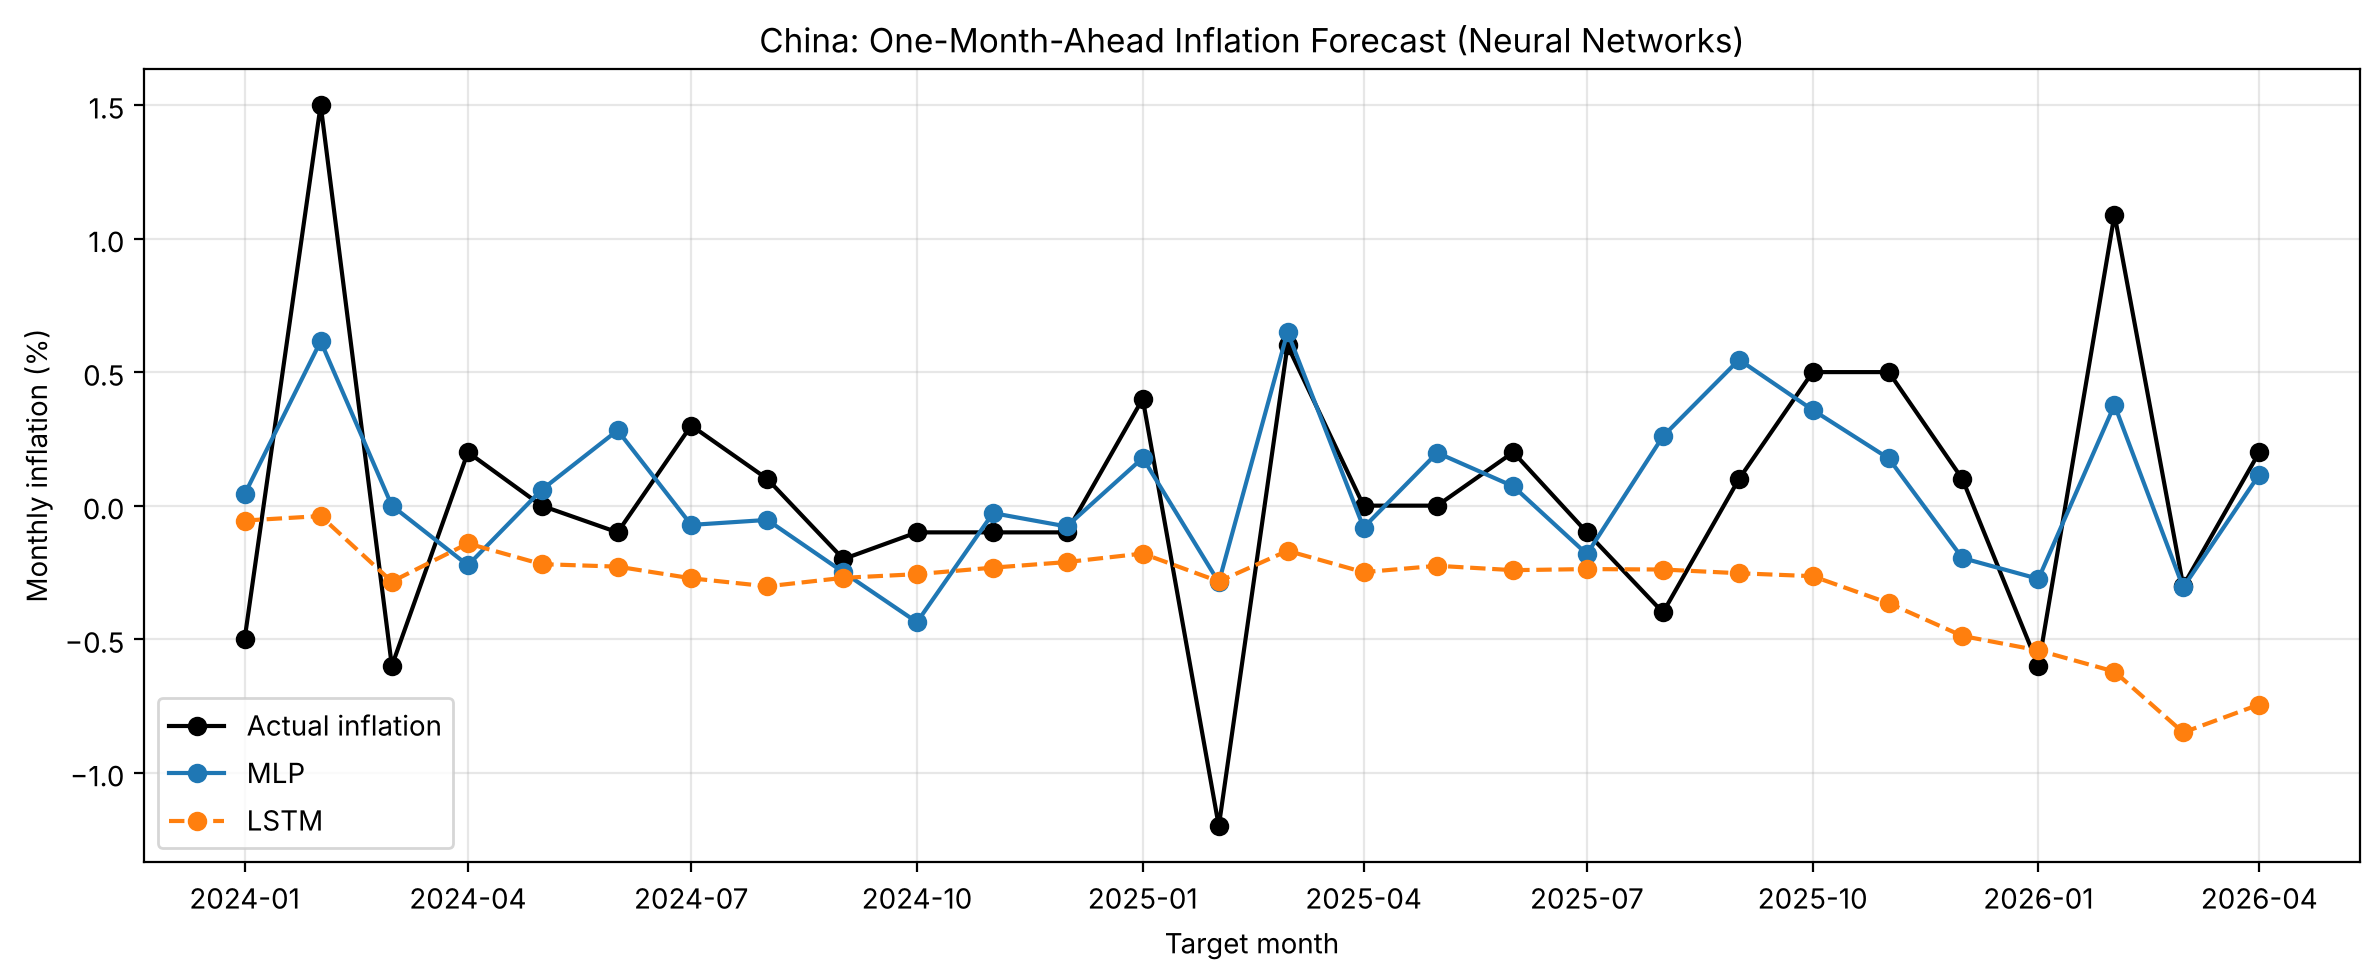

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(test['Date'], y_test, label='Actual inflation', marker='o', color='black')
plt.plot(test['Date'], mlp_pred, label='MLP', marker='o')
plt.plot(test['Date'], lstm_pred, label='LSTM', marker='o', linestyle='--')
plt.title('China: One-Month-Ahead Inflation Forecast (Neural Networks)')
plt.xlabel('Target month'); plt.ylabel('Monthly inflation (%)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('nn_forecast.png', dpi=200); plt.show()

## Conclusion
*(Fill in after running: MLP vs LSTM vs benchmarks and the other models.)*

Note for the report: neural networks need many observations and we only have 228 training months. Results are reproducible (fixed seed), but change somewhat with a different seed (`tf.keras.utils.set_random_seed`), so treat small differences between models with caution.